# Unrolling a cycle

This page goes through every computation that runs a cyclic
[graph](../concepts/#graph) in PyTorch, one step at a time. It uses
the five-node graph of
[Cyclic graph example](../cyclic-graph-example/) with neutral input
names, sets every weight by hand, and draws each step, so you can
check every number with pen and paper.

Read it when you want to see how a feedback edge runs, how many
steps a value needs to reach the output, and what decides when the
loop stops. To train and interpret a model on a cyclic graph, use
the Cyclic graph example instead. A
[directed acyclic graph](../concepts/#dag) (DAG) needs no loop:
`parse_layered()` computes it in one sweep, see
[Layered vs. Adjacency](../layered_vs_adjacency/).

The page shows five facts:

- Every step updates all nodes at once. Each node reads the values
  its source nodes had after the previous step.
- A value moves one edge per step.
- A node keeps nothing of its own previous value unless a cycle or
  a self-loop brings it back. `output` is overwritten every step.
- After K steps, `output` holds every path from an input that is
  at most K edges long.
- The cycle runs across steps, never inside one step, so autograd
  sees an ordinary feedforward computation.

`kpnn2` builds the [spec](../concepts/#spec) — the parsed layout
of the graph — and the `MaskedLinear`. The loop is your own code,
and so is the choice of when it stops (see
[When to stop](#when-to-stop)).

In [ ]:
import random

import numpy as np
import pandas as pd
import torch
from graphviz import Digraph
from matplotlib import pyplot as plt
from matplotlib_inline.backend_inline import (
    set_matplotlib_formats,
)

import kpnn2

torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

set_matplotlib_formats(
    "svg",
    bbox_inches=None,
)
plt.rcParams.update(
    {
        "font.size": 14,
        "font.family": "Liberation Sans",
        "lines.linewidth": 1.5,
        "axes.facecolor": "none",
        "figure.facecolor": "none",
        "savefig.facecolor": "none",
        "svg.fonttype": "none",
    }
)

## The graph and its state vector

Two hidden [nodes](../concepts/#node) feed each other, and each has
its own input. `input_a` feeds `node_a`, `input_b` feeds `node_b`,
`node_a` and `node_b` form a feedback loop, and `node_a` feeds
`output`.

In [ ]:
edgelist = pd.DataFrame(
    {
        "source": [
            "input_a",
            "input_b",
            "node_a",
            "node_b",
            "node_a",
        ],
        "target": [
            "node_a",
            "node_b",
            "node_b",
            "node_a",
            "output",
        ],
    }
)
spec = kpnn2.parse_adjacency(edgelist)

spec.nodes, spec.input_index, spec.output_index

(('input_a', 'input_b', 'node_a', 'node_b', 'output'), (0, 1), (4,))

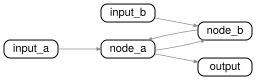

In [ ]:
drawing = Digraph()
drawing.attr(
    rankdir="LR",
    ranksep="0.6",
    nodesep="0.25",
)
drawing.attr(
    "node",
    fontname="Helvetica",
    fontsize="11",
    shape="box",
    style="rounded",
    height="0.25",
    margin="0.06,0.02",
)
drawing.attr(
    "edge",
    color="#8c8c8c",
    arrowsize="0.4",
    penwidth="0.7",
)
for source, target in edgelist.itertuples(index=False):
    drawing.edge(
        source,
        target,
    )
drawing

`parse_adjacency()` puts every node into one
[state vector](../concepts/#state-vector) — one slot per node — in
the alphabetical order of `spec.nodes`. The cycle needs nothing
special: the edge `node_b → node_a` is one more pair of indices,
like every other edge. `spec.to_mask()` holds these arrows as a
square, one row per node and a `1` for each node it reads. The input
rows are empty, because no edge enters an input. So the loop has to
write the input values in before every step.

## Weights you can check by hand

Set every weight to 1 and every bias to 0, and feed `input_a = 10`
and `input_b = 1`. Each path then adds its input value unchanged.
The mask keeps absent edges at zero, so filling the whole weight
square with 1 is safe.

In [ ]:
core = kpnn2.MaskedLinear(spec.to_mask())
with torch.no_grad():
    core.weight.fill_(1.0)
    core.bias.zero_()

x_df = pd.DataFrame(
    {
        "input_a": [10.0],
        "input_b": [1.0],
    }
)
col = kpnn2.align_inputs(
    x_df.columns,
    spec,
)
x = torch.as_tensor(
    x_df.to_numpy()[:, col],
    dtype=torch.float32,
)
x

tensor([[10.,  1.]])

The loop is the `forward()` of `CyclicNet` in the Cyclic graph
example, without the head: write the inputs in, apply `core`,
repeat. `unroll()` keeps the state after every step, with the zero
start as step 0, so `states` has the dims `(step, sample, node)`.

In [ ]:
def unroll(
    spec,
    core,
    x,
    n_steps,
):
    input_index = torch.as_tensor(spec.input_index)
    state = x.new_zeros(
        x.shape[0],
        core.in_features,
    )
    states = [state]
    for _ in range(n_steps):
        state = state.index_copy(
            -1,
            input_index,
            x,
        )
        state = core(state)
        states.append(state)
    return torch.stack(states)


with torch.no_grad():
    states = unroll(
        spec,
        core,
        x,
        n_steps=4,
    )
states.shape

torch.Size([5, 1, 5])

## The loop unrolled over steps

Draw every step as its own column, and the cycle turns into a
pattern that repeats between columns. Each arrow runs from a node in
one column to a node in the next column, one arrow per edge, because
a step reads only the state the previous step left. The feedback
pair `node_a ⇄ node_b` is the crossing between every two columns.
The numbers come from `states`. Dashed boxes are the input values
the loop writes in before the next step.

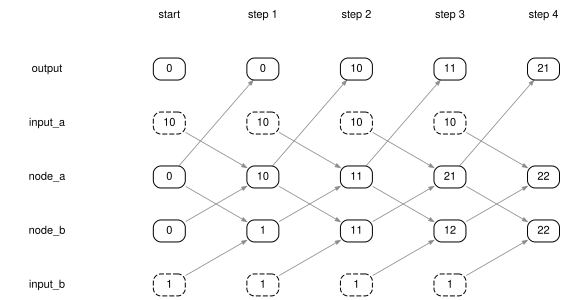

In [ ]:
_ROWS = [
    "output",
    "input_a",
    "node_a",
    "node_b",
    "input_b",
]


def arrows_into(
    edgelist,
    input_nodes,
    node,
    step,
):
    found = set()
    if node in input_nodes or step == 0:
        return found
    for source, target in edgelist.itertuples(index=False):
        if target == node:
            found.add((f"{source}_{step - 1}", f"{node}_{step}"))
            found |= arrows_into(
                edgelist,
                input_nodes,
                source,
                step - 1,
            )
    return found


def draw_unrolled(
    spec,
    edgelist,
    states,
    x,
    highlight=None,
):
    n_steps = len(states) - 1
    slot = {name: i for i, name in enumerate(spec.nodes)}
    x_values = dict(
        zip(
            spec.input_nodes,
            x[0].tolist(),
        )
    )
    drawing = Digraph(engine="neato")
    drawing.attr(
        splines="true",
        outputorder="edgesfirst",
    )
    drawing.attr(
        "node",
        fontname="Helvetica",
        fontsize="11",
        shape="box",
        style="rounded",
        height="0.3",
        width="0.45",
        margin="0.04,0.02",
    )
    drawing.attr(
        "edge",
        arrowsize="0.5",
    )
    for row, name in enumerate(_ROWS):
        drawing.node(
            f"label_{name}",
            name,
            shape="plaintext",
            pos=f"-0.4,{-0.75 * row}!",
            width="1.2",
        )
    for step in range(n_steps + 1):
        drawing.node(
            f"head_{step}",
            "start" if step == 0 else f"step {step}",
            shape="plaintext",
            pos=f"{1.3 * (step + 1)},0.75!",
        )
        for row, name in enumerate(_ROWS):
            if name in x_values:
                if step == n_steps:
                    continue
                value = x_values[name]
                style = "rounded,dashed"
            else:
                value = states[step, 0, slot[name]].item()
                style = "rounded"
            drawing.node(
                f"{name}_{step}",
                f"{value:g}",
                pos=f"{1.3 * (step + 1)},{-0.75 * row}!",
                style=style,
            )
    for step in range(1, n_steps + 1):
        for source, target in edgelist.itertuples(index=False):
            tail = f"{source}_{step - 1}"
            head = f"{target}_{step}"
            if highlight is None:
                color, penwidth = "#8c8c8c", "0.8"
            elif (tail, head) in highlight:
                color, penwidth = "#000000", "1.6"
            else:
                color, penwidth = "#d0d0d0", "0.6"
            drawing.edge(
                tail,
                head,
                color=color,
                penwidth=penwidth,
            )
    return drawing


draw_unrolled(
    spec,
    edgelist,
    states,
    x,
)

Pick any box and add up the boxes its arrows come from: the sum is
the number in the box. `node_a` after step 2 reads 10 from `input_a`
and 1 from `node_b`, and holds 11. With other weights, each source
counts weight × value, and the bias is added on top. In these
figures the tens digit counts the paths from `input_a` and the ones
digit the paths from `input_b`.

Follow one value through it. `input_a = 10` enters `node_a` in step
1, and `output` reads that 10 in step 2. `input_b = 1` enters
`node_b` in step 1, reaches `node_a` in step 2 and `output` in step
3, where 11 = 10 + 1. `output` is still 0 after step 1, because in
step 1 it reads `node_a` from the start.

No arrow points back to an earlier column or stays inside one, so
the computation itself has no cycle. The cycle in the graph became
the crossing that repeats between columns.

## Which paths reach the output

`output` after step 4 depends only on the boxes from which a chain
of arrows leads to it. The figure below draws exactly those arrows
dark and thick.

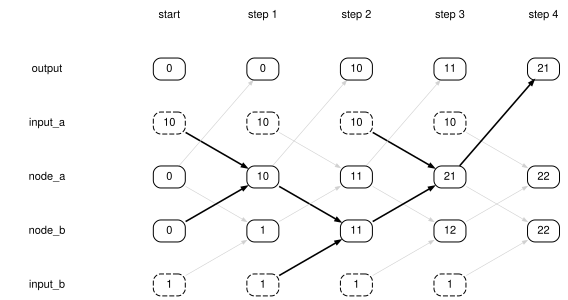

In [ ]:
draw_unrolled(
    spec,
    edgelist,
    states,
    x,
    highlight=arrows_into(
        edgelist,
        spec.input_nodes,
        "output",
        4,
    ),
)

Three paths run along the dark arrows:

- `input_a → node_a → output` adds 10.
- `input_b → node_b → node_a → output` adds 1.
- `input_a → node_a → node_b → node_a → output` goes once around the
  loop and adds 10.

Together they give 21, the value of `output` after step 4. Each
extra step adds the paths that are one edge longer. The dark arrow
from `node_b` at the start carries 0. The inputs written before the
last step have no dark arrow: they reach only the nodes one edge
away, never `output`.

With weights other than 1, each path adds its input value times the
product of the weights along it. A nonlinear activation breaks this
clean sum, but not which paths can contribute.

## What autograd sees

Autograd records the computation the way the figure draws it: one
application of `core` per step, each reading the state of the step
before. Backpropagation follows the dark arrows backwards, so an
input gets a gradient only if a dark arrow leaves it. Here are the
dark arrows after two steps:

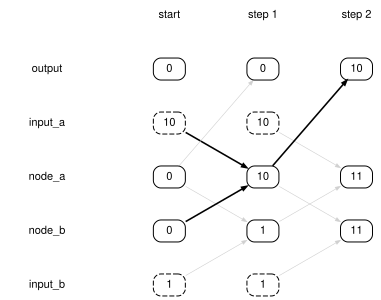

In [ ]:
draw_unrolled(
    spec,
    edgelist,
    states[:3],
    x,
    highlight=arrows_into(
        edgelist,
        spec.input_nodes,
        "output",
        2,
    ),
)

No dark arrow leaves `input_b`. With two steps, `input_b` gets no
gradient, so training cannot learn anything from it. With three or
more steps a dark arrow leaves `input_b`, as in the step-4 figure
above. This is why the controls in the Cyclic graph example run three steps: the
path from the input of `node_b` to `output` is three edges long.

## Without the feedback edge

Remove the edge `node_a → node_b`, and the graph is a DAG. Its
longest path from an input to `output`,
`input_b → node_b → node_a → output`, has three edges. Run the same
loop on it with the same hand-set weights:

In [ ]:
is_feedback = (edgelist["source"] == "node_a") & (
    edgelist["target"] == "node_b"
)
dag_edgelist = edgelist[~is_feedback]
dag_spec = kpnn2.parse_adjacency(dag_edgelist)
dag_core = kpnn2.MaskedLinear(dag_spec.to_mask())
with torch.no_grad():
    dag_core.weight.fill_(1.0)
    dag_core.bias.zero_()
    # Same input nodes as spec, so x still lines up.
    dag_states = unroll(
        dag_spec,
        dag_core,
        x,
        n_steps=5,
    )

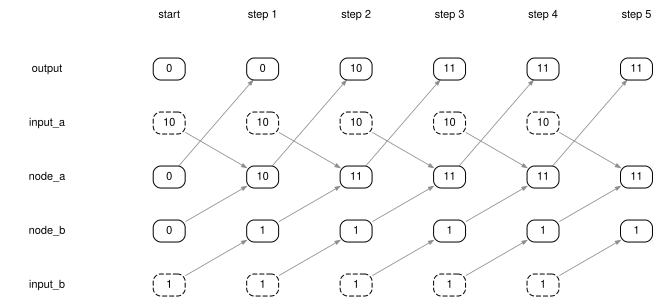

In [ ]:
draw_unrolled(
    dag_spec,
    dag_edgelist,
    dag_states,
    x,
)

From step 3 on, every column is the same: every path has arrived,
and no path is longer than three edges. On a DAG the loop settles by
itself once the step count reaches the longest path, and more steps
cost time but change nothing. For a DAG, `parse_layered()` with one
sweep through its layers is the direct route. A cycle makes the
paths endless, so with a cycle something has to decide when the loop
stops.

## The loop in formulas

Write n for the number of nodes, 5 here. For one sample:

- `h[t]` is the state after step t, a vector of length n, with
  `h[0] = 0`.
- `W` is the n × n weight that `core` applies,
  `core.effective_weight()`. `W[v, u]` is the weight of the edge
  `u → v`, and 0 where there is no edge.
- `b` is the bias, length n.
- `x̂` has length n and holds the input values in the input slots
  and 0 elsewhere.

One step overwrites the input slots with `x̂` and applies `core`.
What the input slots held before is lost, so it never reaches `W`.
Let `A` be `W` with its input columns set to 0, and let
`u = W x̂ + b`. Then

```text
h[t] = A h[t-1] + u

h[K] = u + A u + A² u + ... + A^(K-1) u
```

`u` holds the one-edge paths out of the inputs, and every product
with `A` makes each path one edge longer. So `h[K]` holds every path
of at most K edges, as the figures showed. If every eigenvalue of
`A` has magnitude below 1 (a spectral radius below 1), the sum
converges as K grows, to the steady state

```text
h* = (I - A)⁻¹ u
```

A fixed K cuts this sum off after K terms. With an activation `f`, a
step is `h[t] = f(A h[t-1] + u)`. The sum no longer splits into
paths, but the steady state is still the state that one more step
leaves unchanged.

`loop_terms()` builds `A` and `u` from a `MaskedLinear`:

In [ ]:
def loop_terms(
    spec,
    core,
    x,
):
    weight = core.effective_weight().detach()
    x_hat = torch.zeros(core.in_features)
    x_hat[list(spec.input_index)] = x[0]
    a = weight.clone()
    a[:, list(spec.input_index)] = 0.0
    u = weight @ x_hat + core.bias.detach()
    return a, u


a, u = loop_terms(
    spec,
    core,
    x,
)
torch.linalg.eigvals(a).abs().max()

tensor(1.)

With every weight 1, the loop `node_a ⇄ node_b` gives `A` the
eigenvalues 1 and −1, so the spectral radius is 1. The sum never
converges, and the values in the figures keep growing.

## When to stop

Everything above follows from the graph. What differs between
models on a cyclic graph is when the loop stops. `kpnn2` does not
decide this and ships none of these loops. It builds the spec and
the `MaskedLinear`. The loop, the stopping rule, any convergence
check or stability penalty, and any custom backward pass are code in
your own `forward()`. Three choices are common.

### A fixed number of steps

The Cyclic graph example and this page use a fixed number of steps
K. `output` holds every path of at most K edges, and autograd
backpropagates through K applications of `core`. Pick K at least
as long as the longest input-to-output path the model should use. A
shorter K cuts those inputs off, as the two-step figure shows. The
result depends on K, and when the loop amplifies, as here, values
keep growing with K.

### Run until the state stops changing

Repeat the step until the change from one step to the next falls
below a tolerance, then read the steady state `h*`. The result no
longer depends on a step count. For a signaling network it reads as
the state the network settles in under a constant input. It exists
only if the loop shrinks what goes around it, that is, if the
spectral radius of `A` is below 1.

Set both feedback weights to 0.5 instead of 1. A lap around
`node_a ⇄ node_b` then multiplies by 0.25, and the loop settles.
`run_to_steady_state()` stops once no slot changes by more than
`1e-6`, and returns `None` as the step count if that never happens
within `max_steps`:

In [ ]:
def run_to_steady_state(
    spec,
    core,
    x,
    tolerance=1e-6,
    max_steps=500,
):
    input_index = torch.as_tensor(spec.input_index)
    state = x.new_zeros(
        x.shape[0],
        core.in_features,
    )
    for step in range(1, max_steps + 1):
        previous = state
        state = core(
            state.index_copy(
                -1,
                input_index,
                x,
            )
        )
        if (state - previous).abs().max() < tolerance:
            return state, step
    return state, None


damped = kpnn2.MaskedLinear(spec.to_mask())
with torch.no_grad():
    damped.weight.fill_(1.0)
    damped.bias.zero_()
    damped.weight[
        spec.node_units("node_b"),
        spec.node_units("node_a"),
    ] = 0.5
    damped.weight[
        spec.node_units("node_a"),
        spec.node_units("node_b"),
    ] = 0.5
    steps_to_settle = {
        name: run_to_steady_state(
            spec,
            layer,
            x,
        )[1]
        for name, layer in [
            ("feedback weights 1", core),
            ("feedback weights 0.5", damped),
        ]
    }
steps_to_settle

{'feedback weights 1': None, 'feedback weights 0.5': 25}

With feedback weights 1 the loop never settles. With feedback
weights 0.5 it settles after 25 steps. The plot at the end of this
section shows where.

Backpropagating through every step of a long run stores every step.
A steady-state model can instead compute the gradient at `h*` with an
implicit (adjoint) backward pass, a custom `torch.autograd.Function`
you write. To keep the loop stable during training, penalize the
spectral radius in your loss or constrain the weights.

LEMBAS — large-scale knowledge-embedded artificial signaling
networks (Nilsson et al., 2022) — is built this way on a signaling
network. It has one state per node and one weight per edge. All
nodes update together from zero, with the ligand input added at
every step, until the state stops changing or a step limit is
reached. It scales its weights to a spectral radius below 1 at the
start, penalizes the spectral radius during training, and computes
gradients at the steady state with its own backward pass instead of
storing every step.

### Integrate in continuous time

Read each step as one tick of a clock, and the loop becomes an
ordinary differential equation (ODE) in a time `τ`:

```text
dh/dτ = A h + u - h
```

With an activation `f`, the right-hand side is `f(A h + u) - h`. One
Euler step of size 1 gives `h + 1 · (A h + u - h) = A h + u`, which
is the loop. A smaller step, or an adaptive solver, follows the same
equation more finely. It comes to rest where `A h + u = h`, at the
same steady state `h*`. The stopping rule becomes an end time or,
again, a steady state.

To use it, write the right-hand side as a module that calls
`core`, and integrate it with your own Euler loop or with an ODE
solver such as [torchdiffeq](https://github.com/rtqichen/torchdiffeq).
`integrate_euler()` is the Euler loop, and it keeps the state at
every time point:

In [ ]:
def integrate_euler(
    spec,
    core,
    x,
    step_size,
    end_time,
):
    input_index = torch.as_tensor(spec.input_index)
    state = x.new_zeros(
        x.shape[0],
        core.in_features,
    )
    states = [state]
    for _ in range(round(end_time / step_size)):
        state = state.index_copy(
            -1,
            input_index,
            x,
        )
        state = state + step_size * (core(state) - state)
        states.append(state)
    return torch.stack(states)

### The three rules side by side

Follow `output` for 30 steps under each rule: the loop with feedback
weights 1, the loop with feedback weights 0.5, and the Euler loop
with step size 0.1 on the feedback-0.5 weights. The steady state
comes from the formula.

In [ ]:
n_steps = 30
step_size = 0.1
with torch.no_grad():
    growing = unroll(
        spec,
        core,
        x,
        n_steps,
    )
    settling = unroll(
        spec,
        damped,
        x,
        n_steps,
    )
    euler = integrate_euler(
        spec,
        damped,
        x,
        step_size,
        end_time=float(n_steps),
    )
    a, u = loop_terms(
        spec,
        damped,
        x,
    )
    steady_state = torch.linalg.solve(
        torch.eye(len(u)) - a,
        u,
    )

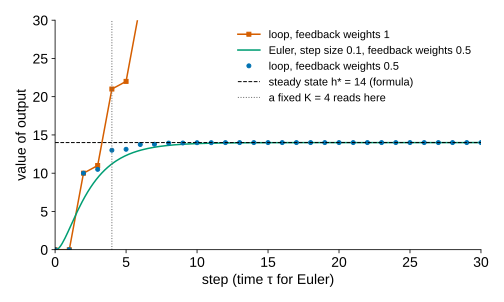

In [ ]:
output_slot = spec.output_index[0]
fixed_k = 4
steps = np.arange(n_steps + 1)
times = step_size * np.arange(len(euler))

fig, ax = plt.subplots(figsize=(7.0, 4.2))
ax.plot(
    steps,
    growing[:, 0, output_slot].numpy(),
    color="#D55E00",
    marker="s",
    markersize=4,
    label="loop, feedback weights 1",
)
ax.plot(
    times,
    euler[:, 0, output_slot].numpy(),
    color="#009E73",
    linestyle="-",
    label="Euler, step size 0.1, feedback weights 0.5",
)
ax.plot(
    steps,
    settling[:, 0, output_slot].numpy(),
    color="#0072B2",
    linestyle="none",
    marker="o",
    markersize=4,
    label="loop, feedback weights 0.5",
)
ax.axhline(
    steady_state[output_slot].item(),
    color="black",
    linestyle="--",
    linewidth=1.0,
    label=f"steady state h* = {steady_state[output_slot]:g} (formula)",
)
ax.axvline(
    fixed_k,
    color="#666666",
    linestyle=":",
    linewidth=1.0,
    label=f"a fixed K = {fixed_k} reads here",
)
ax.set_xlim(0, n_steps)
ax.set_ylim(0, 30)
ax.set_xlabel("step (time τ for Euler)")
ax.set_ylabel("value of output")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=11,
)
fig.tight_layout()
plt.show()

The loop with feedback weights 1 leaves the plot after a few steps
and keeps growing. With feedback weights 0.5, the loop and the Euler
loop both come to rest on the dashed line, the steady state the
formula gives. A fixed K = 4 reads `output` before it gets there.

The three rules agree only when the loop settles and K is large
enough to come close to where it settles. A fixed K reads the sum
after K terms, wherever it stands. The steady-state and ODE rules
read where the loop comes to rest, and they require that it does.

## Where to go next

- [Cyclic graph example](../cyclic-graph-example/) trains this loop
  on simulated data and scores the nodes at every step.
- [Time-series example](../time-series-example/) writes a different
  `x_t` in at each step instead of the same `x`.
- [Layered vs. Adjacency](../layered_vs_adjacency/) compares this
  layout with `parse_layered()`.
- [PackedLinear](../packed_linear/) replaces `MaskedLinear` when the
  `(n, n)` square would strain RAM.

## References

- Nilsson A, Peters JM, Meimetis N, Bryson B, Lauffenburger DA
  (2022). Artificial neural networks enable genome-scale simulations
  of intracellular signaling. *Nature Communications* 13:3069.
  [doi:10.1038/s41467-022-30684-y](https://doi.org/10.1038/s41467-022-30684-y)